# 00 — Python, NumPy ve Matplotlib Temelleri

Bu notebook, sonraki notebook'lardaki kodu okuyabilmen için gereken **en az** Python bilgisini verir. Hepsini ezberlemen gerekmiyor; sonraki notebook'larda bir şeye takılırsan buraya dönersin.

**Notebook nasıl kullanılır?**
- Gri kutular **kod hücresi**dir. Hücreye tıkla ve **Shift + Enter**'a bas: hücre çalışır, çıktısı altında görünür.
- Hücreleri **yukarıdan aşağıya sırayla** çalıştır. Bir hücre, önceki hücrelerde tanımlanan şeyleri kullanır.
- Bir şey bozulursa üst menüden **Kernel → Restart & Run All** ile her şeyi baştan çalıştırabilirsin.
- `#` ile başlayan satırlar **yorumdur**: Python onları çalıştırmaz, sadece insanlar için açıklamadır.

**Seri haritası:**

| Notebook | Konu | Kitaptaki bölüm |
|---|---|---|
| 00 | Python, NumPy, Matplotlib temelleri | — |
| 01 | Gradient descent (tek boyut) | 4 |
| 02 | Steepest descent, Newton–Raphson, finite differences | 5, 6.1 |
| 03 | Çok boyutlu optimization ve convergence rate | 6, 7 |
| 04 | Regression: least squares, overfitting, nonlinear regression | 8 |
| 05 | SGD, mini-batch, AdaGrad, RMSProp, Adam | 9 |
| 06 | Kolektif öğrenme: oylama, bias–variance | 10 |

## 1. Değişkenler ve sayılar

Bir **değişken**, bir değeri sakladığımız isimli kutudur. `=` işareti "sağdaki değeri soldaki kutuya koy" demektir (matematikteki eşitlik değil, **atama**dır).

In [1]:
x = 3          # x adlı kutuya 3 koy
eps = 0.05     # ondalık sayılarda nokta kullanılır (virgül değil)
y = x ** 2     # ** üs almaktır: 3 üzeri 2
print(x, eps, y)

3 0.05 9


**Temel işlemler:** `+` toplama, `-` çıkarma, `*` çarpma, `/` bölme, `**` üs alma.

`print(...)` parantez içindekileri ekrana yazar. Bir notebook hücresinin **son satırı** bir değerse, `print` yazmasan da o değer gösterilir.

In [2]:
a = 10
a = a - 2      # a'nın eski değerinden 2 çıkar, sonucu yine a'ya koy (a artık 8)
a              # son satır olduğu için değeri gösterilir

8

Bu `a = a - 2` kalıbı çok önemli: **gradient descent tam olarak budur**. `x = x - eps * egim` satırı "x'i, eğimin küçük bir katı kadar azalt" demektir.

## 2. Fonksiyon tanımlamak

Matematikteki $f(x) = x^2$'yi Python'da `def` ile yazarız. `return` fonksiyonun geri verdiği değerdir.

In [3]:
def f(x):
    return x ** 2          # f(x) = x^2

def df(x):
    return 2 * x           # derivative: f'(x) = 2x

print("f(3) =", f(3))
print("f'(3) =", df(3))

f(3) = 9
f'(3) = 6


**Girinti (indentation) önemlidir.** `def` satırından sonraki satırlar 4 boşluk içeride yazılır; Python fonksiyonun gövdesinin nerede bittiğini böyle anlar.

## 3. Döngüler: `for` ve `while`

Optimization algoritmaları bir adımı **tekrar tekrar** uygular. Bunun için döngü kullanırız.

`for` döngüsü: "şu kadar kez tekrarla".

In [4]:
for i in range(5):     # i sırayla 0, 1, 2, 3, 4 olur
    print("adım", i)

adım 0
adım 1
adım 2
adım 3
adım 4


`while` döngüsü: "koşul doğru olduğu sürece tekrarla". Stopping condition'lı algoritmalarda bunu kullanırız.

In [5]:
x = 100
adim = 0
while x > 1:           # x 1'den büyük olduğu sürece devam et
    x = x / 2          # x'i yarıya indir
    adim = adim + 1
print("x =", x, "| kaç adım sürdü:", adim)

x = 0.78125 | kaç adım sürdü: 7


## 4. Listeler ve geçmişi kaydetmek

Algoritmanın her adımda nereye gittiğini görmek için değerleri bir **listeye** ekleriz. Liste köşeli parantezle yazılır; `.append(...)` sona eleman ekler.

In [6]:
gecmis = []                # boş liste
x = 5.0
for i in range(4):
    gecmis.append(x)       # şimdiki x'i kaydet
    x = x * 0.5
print(gecmis)
print("ilk eleman:", gecmis[0], "| son eleman:", gecmis[-1], "| uzunluk:", len(gecmis))

[5.0, 2.5, 1.25, 0.625]
ilk eleman: 5.0 | son eleman: 0.625 | uzunluk: 4


Python'da sayma **0'dan** başlar: `gecmis[0]` ilk eleman. `gecmis[-1]` sondan birinci (son) eleman.

## 5. NumPy: sayı dizileri ve vector/matrix

**NumPy**, sayılarla toplu işlem yapan kütüphanedir. `import numpy as np` ile yükleriz; sonra `np.` ile kullanırız.

NumPy'ın en önemli özelliği: bir dizinin **tüm elemanlarına aynı anda** işlem yapabilir.

In [7]:
import numpy as np

v = np.array([1.0, 2.0, 3.0])   # bir vector
print(v * 2)       # her eleman 2 ile çarpılır
print(v ** 2)      # her elemanın karesi
print(np.sum(v))   # toplam: 6
print(np.mean(v))  # ortalama (mean): 2

[2. 4. 6.]
[1. 4. 9.]
6.0
2.0


Çok boyutlu optimization'da $x = (x_1, x_2)$ bir vector'dür; NumPy dizisiyle temsil ederiz. Matrix'ler de "dizilerin dizisi"dir.

In [8]:
x = np.array([2.0, 2.0])
grad = np.array([2 * x[0], 4 * x[1]])     # f = x1^2 + 2 x2^2 için gradient
print("x =", x, " gradient =", grad)

Q = np.array([[1.0, 0.5],
              [0.5, 2.0]])               # 2x2 bir matrix
print("Q @ x =", Q @ x)                  # @ işareti matrix çarpımıdır
print("Q'nun inverse'ü:\n", np.linalg.inv(Q))
print("determinant:", np.linalg.det(Q))

x = [2. 2.]  gradient = [4. 8.]
Q @ x = [3. 5.]
Q'nun inverse'ü:
 [[ 1.14285714 -0.28571429]
 [-0.28571429  0.57142857]]
determinant: 1.75


| Yazım | Anlamı |
|---|---|
| `x[0]`, `x[1]` | vector'ün 1. ve 2. elemanı |
| `A @ B` | matrix çarpımı |
| `A.T` | transpose |
| `np.linalg.inv(A)` | inverse |
| `np.linalg.solve(A, b)` | $Ax = b$ denklemini çöz (inverse almaktan daha güvenli) |
| `np.linspace(a, b, n)` | $a$ ile $b$ arasında eşit aralıklı $n$ sayı |
| `np.sqrt`, `np.sin`, `np.cos`, `np.exp`, `np.log` | matematik fonksiyonları (dizinin her elemanına uygulanır) |

## 6. Rastgele sayılar

SGD ve kolektif öğrenmede rastgelelik kullanırız. `rng` bir rastgele sayı üreticidir; `seed` (tohum) aynı verilirse her çalıştırmada **aynı** rastgele sayılar gelir, böylece sonuçlar tekrar üretilebilir.

In [9]:
rng = np.random.default_rng(seed=0)
print(rng.normal(0, 1, size=3))      # mean 0, standard deviation 1 olan normal distribution'dan 3 sayı (MATLAB'daki randn)
print(rng.integers(0, 10, size=5))   # 0 ile 9 arasında 5 rastgele tam sayı

[ 0.12573022 -0.13210486  0.64042265]
[0 0 1 8 6]


## 7. Matplotlib ile grafik çizmek

`matplotlib.pyplot` grafik çizer. Temel kalıp hep aynıdır: x değerleri, y değerleri, `plt.plot(x, y)`, sonra etiketler.

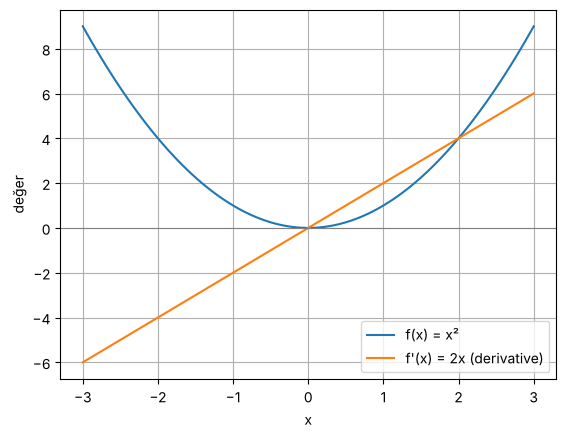

In [10]:
import matplotlib.pyplot as plt

xs = np.linspace(-3, 3, 100)       # -3'ten 3'e 100 nokta
plt.plot(xs, xs ** 2, label="f(x) = x²")
plt.plot(xs, 2 * xs, label="f'(x) = 2x (derivative)")
plt.axhline(0, color="gray", linewidth=0.8)   # y = 0 yatay çizgisi
plt.xlabel("x")
plt.ylabel("değer")
plt.legend()                       # etiket kutusunu göster
plt.grid(True)
plt.show()

## 8. Mini alıştırma

Aşağıdaki hücrede `f(x) = (x - 1)**2` fonksiyonunu ve derivative'ini tanımla, sonra $-2$ ile $4$ arasında ikisini aynı grafikte çiz. Derivative'in sıfır olduğu yer, function'ın minimum'u mu?

İpucu: $(x-1)^2$'nin derivative'i $2(x-1)$'dir.

In [11]:
# Buraya kendi kodunu yaz. Takılırsan bir sonraki hücrede çözüm var.

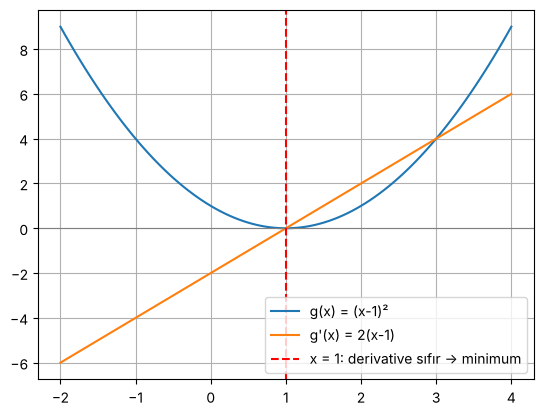

In [12]:
# ÇÖZÜM
def g(x):
    return (x - 1) ** 2

def dg(x):
    return 2 * (x - 1)

xs = np.linspace(-2, 4, 100)
plt.plot(xs, g(xs), label="g(x) = (x-1)²")
plt.plot(xs, dg(xs), label="g'(x) = 2(x-1)")
plt.axhline(0, color="gray", linewidth=0.8)
plt.axvline(1, color="red", linestyle="--", label="x = 1: derivative sıfır → minimum")
plt.legend(); plt.grid(True); plt.show()

**Bu notebook'ta öğrendiklerin:** değişken ve atama (`x = x - ...`), fonksiyon (`def`), döngüler (`for`, `while`), listeye kayıt (`append`), NumPy dizileri ve matrix işlemleri, grafik çizme. Bunlar sonraki notebook'lardaki her algoritmanın yapı taşları.